# 02. Total Sori Imputation

This notebook imputes the missing `n_sori_total` value for individual H15. We first examine the distribution of `n_sori_total` to evaluate whether a simple imputation strategy (mean or median) is appropriate, and then explore its relationship with frond morphometrics to assess whether a regression-based approach is justified instead. The imputed dataset generated here is used as input for the subsequent notebook, focused on imputing H15's row-level sori distribution.

## 1. Import Libraries

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence
from statsmodels.stats.multitest import multipletests
from scipy.stats import pearsonr, spearmanr, skew, shapiro
from sklearn.linear_model import TheilSenRegressor
from sklearn.preprocessing import StandardScaler

## 2. Load Data

We load the cleaned datasets exported by `01_data_cleaning`.

In [83]:
df_fronds_clean = pd.read_csv("../data/processed/fronds_clean.csv")
df_sori_clean = pd.read_csv("../data/processed/sori_clean.csv")



Quick check of the loaded data:

In [84]:
df_fronds_clean.head()

,individual_id,frond_length_cm,frond_width_cm,n_sori_total,leaf_area_cm2
0,H01,63.0,8.4,1656.0,280.0
1,H02,42.0,5.8,1554.0,130.0
2,H03,68.5,8.1,1728.0,266.0
3,H04,66.0,7.1,1826.0,216.0
4,H05,60.7,6.0,1456.0,194.0


In [85]:
df_sori_clean.head()

,individual_id,row_id,n_sori_per_row
0,H01,86,0.0
1,H01,85,0.0
2,H01,84,0.0
3,H01,83,0.0
4,H01,82,0.0


## 3. Feature Engineering: Pinna Rows per Individual

As established in `01_data_cleaning`, individual H15 is missing both its `n_sori_total` value and all of its row-level sori data. Before exploring candidate predictors for imputing `n_sori_total`, we enrich the Fronds dataset with a new feature: the number of pinna-pair rows recorded for each individual in the Sori dataset.



In [86]:
pinna_row_counts = df_sori_clean.groupby("individual_id")["row_id"].count()

df_fronds_features = pd.merge(df_fronds_clean, pinna_row_counts, on="individual_id", how="left")
df_fronds_features = df_fronds_features.rename(columns={"row_id": "n_pinna_rows"})

df_fronds_features.head()

,individual_id,frond_length_cm,frond_width_cm,n_sori_total,leaf_area_cm2,n_pinna_rows
0,H01,63.0,8.4,1656.0,280.0,86
1,H02,42.0,5.8,1554.0,130.0,59
2,H03,68.5,8.1,1728.0,266.0,80
3,H04,66.0,7.1,1826.0,216.0,89
4,H05,60.7,6.0,1456.0,194.0,82


With `n_pinna_rows` added, we set H15 aside and keep only the 23 individuals with a complete `n_sori_total`, which will be used in the exploratory analysis that follows.

In [87]:
df_fronds_notnull = df_fronds_features.loc[df_fronds_features["n_sori_total"].notnull()]

print(f"Shape after removing H15: {df_fronds_notnull.shape}")
print(f"Remaining missing values in n_sori_total: {df_fronds_notnull['n_sori_total'].isna().sum()}")

Shape after removing H15: (23, 6)
Remaining missing values in n_sori_total: 0


## 4. Exploratory Analysis

We start by examining the distribution of `n_sori_total` to decide whether a simple imputation strategy is appropriate. If not, we explore its relationship with the frond morphometrics available, `frond_length_cm`, `frond_width_cm`, `leaf_area_cm2`, and `n_pinna_rows`, to evaluate whether a regression-based approach is justified instead.


Before examining `n_sori_total` specifically, we look at the full set of morphometric variables together, to get a general sense of scale and variability across the 23 individuals with complete data.

In [88]:
df_fronds_notnull[["frond_length_cm", "frond_width_cm", "leaf_area_cm2", "n_pinna_rows", "n_sori_total"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
frond_length_cm,23.0,59.11,10.01,30.1,55.44,60.7,65.9,74.1
frond_width_cm,23.0,6.95,0.99,5.6,6.10,6.9,7.8,9.1
leaf_area_cm2,23.0,206.98,53.30,80.0,183.80,205.0,233.0,291.0
n_pinna_rows,23.0,79.78,13.11,42.0,73.00,82.0,87.0,103.0
n_sori_total,23.0,1414.87,432.68,482.0,1268.00,1554.0,1661.0,2036.0


### 4.1 Distribution of n_sori_total

We define a reusable helper function to plot the distribution of a variable (boxplot + histogram + normality test), used both for `n_sori_total` and later for the candidate predictor variables.

In [89]:
def plot_dist(data, name, figsize=(7, 6)):
    """
    Plots a boxplot + histogram with KDE for a data series,
    annotating skewness and the Shapiro-Wilk test p-value.
    """
    skew_val = skew(data)
    stat, p_shapiro = shapiro(data)

    fig, (ax_box, ax_hist) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.35, 1)},
        figsize=figsize
    )

    sns.boxplot(x=data, color="#e2e8f0", width=0.3, fliersize=5, ax=ax_box)
    sns.histplot(data, kde=True, ax=ax_hist)

    ax_box.set(yticks=[])
    ax_hist.set_xlabel(name)
    fig.suptitle(f"{name}\nskew = {skew_val:.3f}  |  Shapiro-Wilk p = {p_shapiro:.3f}")
    plt.tight_layout()
    plt.show()

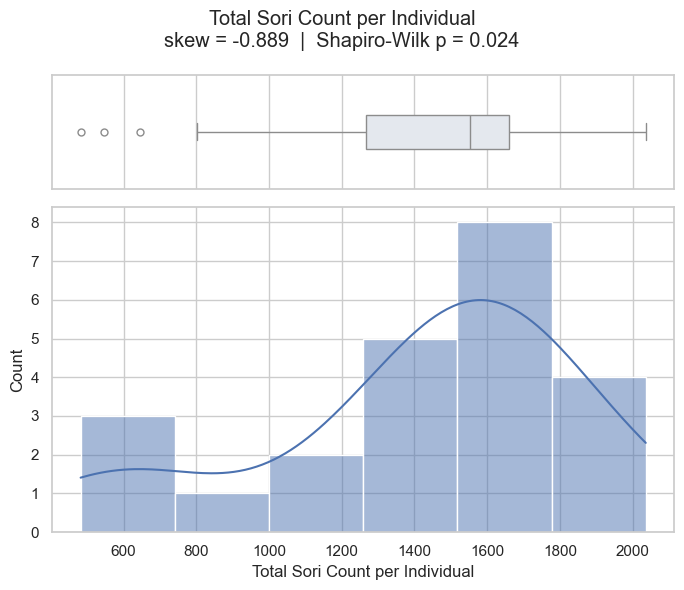

In [90]:
plot_dist(df_fronds_notnull["n_sori_total"], "Total Sori Count per Individual")

The distribution is left-skewed (skew = -0.889) and fails the Shapiro-Wilk normality test (p = 0.024), with visible outliers in the boxplot. This means the mean would not be a robust choice for simple imputation, the median would be preferable, and Spearman (not Pearson) is the appropriate correlation method going forward. Whether a fixed value like the median is sufficient, or a regression-based approach is better justified, depends on how strongly `n_sori_total` relates to the available frond morphometrics, examined next.

### 4.2 Scatter Plots vs. Candidate Predictors

We plot `n_sori_total` against each of the four morphometric variables available: `frond_length_cm`, `frond_width_cm`, `leaf_area_cm2`, and `n_pinna_rows`.

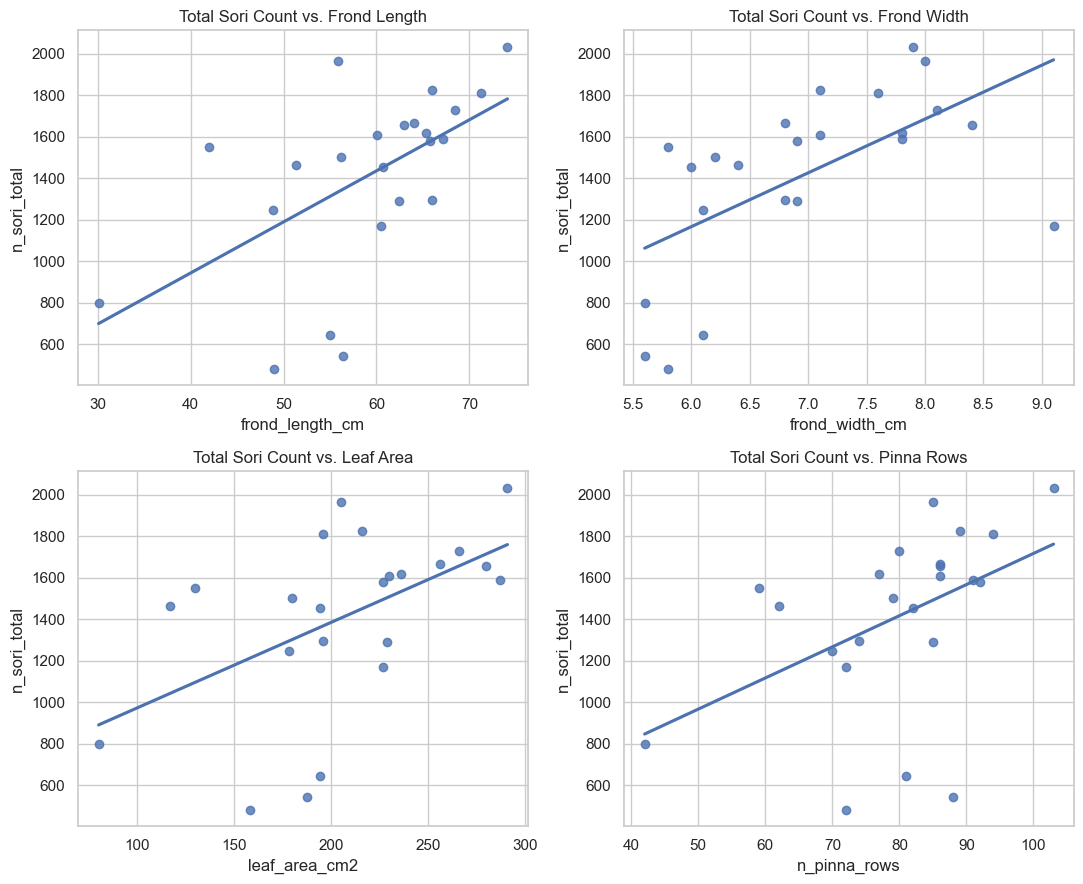

In [91]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

sns.regplot(x="frond_length_cm", y="n_sori_total", data=df_fronds_notnull, ax=axes[0], ci=None)
axes[0].set_title("Total Sori Count vs. Frond Length")

sns.regplot(x="frond_width_cm", y="n_sori_total", data=df_fronds_notnull, ax=axes[1], ci=None)
axes[1].set_title("Total Sori Count vs. Frond Width")

sns.regplot(x="leaf_area_cm2", y="n_sori_total", data=df_fronds_notnull, ax=axes[2], ci=None)
axes[2].set_title("Total Sori Count vs. Leaf Area")

sns.regplot(x="n_pinna_rows", y="n_sori_total", data=df_fronds_notnull, ax=axes[3], ci=None)
axes[3].set_title("Total Sori Count vs. Pinna Rows")

plt.tight_layout()
plt.show()

The scatter plots show a reasonably clear linear trend between `n_sori_total` and each of the four candidate predictors. Consistent with the outliers already identified in the boxplot of `n_sori_total` in Section 4.1, several points fall below the fitted trend line across all four panels, the same low-count individuals that stood out as outliers there also appear as departures from the linear pattern here, rather than being isolated to a single predictor.

### 4.3 Spearman Correlation Matrix

Pearson correlation assumes normally distributed, linearly related variables and is sensitive to outliers. Since Section 4.1 showed that `n_sori_total` is left-skewed (skew = -0.889), fails the Shapiro-Wilk normality test (p = 0.024), and contains outliers, we use Spearman correlation instead, it only assumes a monotonic relationship and is based on ranks rather than raw values, making it more robust to both non-normality and outliers.

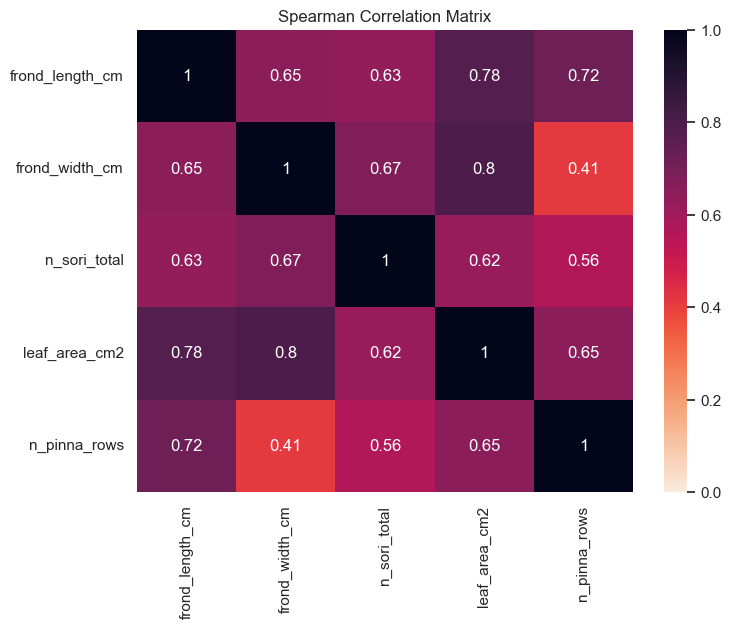

In [92]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df_fronds_notnull.drop(columns=["individual_id"]).corr(method="spearman"),
    annot=True,
    cmap="rocket_r",
    vmin=0, vmax=1
)
plt.yticks(rotation=0)
plt.title("Spearman Correlation Matrix")
plt.show()

The correlation coefficients alone show the strength and direction of each relationship, but not whether it is likely to reflect a real association or simply chance, given our small sample (n = 23). We test each correlation against the null hypothesis of no monotonic relationship (rho = 0), using a significance threshold of alpha = 0.05.

In [93]:
predictors = ["frond_length_cm", "frond_width_cm", "leaf_area_cm2", "n_pinna_rows"]

for col in predictors:
    rho, p_value = spearmanr(df_fronds_notnull[col], df_fronds_notnull["n_sori_total"])
    print(f"{col}: rho = {rho:.3f}, p = {p_value:.4f}")

frond_length_cm: rho = 0.632, p = 0.0012
frond_width_cm: rho = 0.672, p = 0.0004
leaf_area_cm2: rho = 0.620, p = 0.0016
n_pinna_rows: rho = 0.560, p = 0.0055


Since we run 4 simultaneous correlation tests (one per predictor), we apply the Bonferroni correction to control the risk of false positives, adjusting the significance threshold from 0.05 to approximately 0.0125 (0.05/4).

In [94]:
reject_bonf, pvals_bonf, _, _ = multipletests(
    [spearmanr(df_fronds_notnull[col], df_fronds_notnull["n_sori_total"])[1] for col in predictors],
    alpha=0.05, method="bonferroni"
)

for col, p_bonf, sig in zip(predictors, pvals_bonf, reject_bonf):
    print(f"{col}: p_bonferroni = {p_bonf:.4f}, significant = {sig}")

frond_length_cm: p_bonferroni = 0.0049, significant = True
frond_width_cm: p_bonferroni = 0.0018, significant = True
leaf_area_cm2: p_bonferroni = 0.0064, significant = True
n_pinna_rows: p_bonferroni = 0.0220, significant = True


The visual relationship observed in the scatter plots is confirmed quantitatively here: n_sori_total shows moderate to high Spearman correlations with all four predictors, 0.63 (frond_length_cm), 0.67 (frond_width_cm), 0.62 (leaf_area_cm2), and 0.56 (n_pinna_rows), with frond_width_cm and frond_length_cm showing the strongest association. After Bonferroni correction for the four simultaneous tests, all four correlations remain statistically significant (p_bonferroni = 0.0049, 0.0018, 0.0064, and 0.0220, respectively), so none can be attributed to chance given this sample size. n_pinna_rows clears the corrected threshold with the narrowest margin of the four.

### 4.4 Investigating Why leaf_area_cm2 Underperforms

At first glance, one would expect `leaf_area_cm2`, which combines width and length, to be more informative than either dimension alone. However, `leaf_area_cm2` shows the *lowest* correlation with `n_sori_total` (0.62) among the four predictors, even below `frond_length_cm` (0.63) and `frond_width_cm` (0.67). Two possible explanations are worth considering:

1. **Additional measurement error**: `leaf_area_cm2` was calculated using digital image analysis (ImageJ), which introduces several sources of noise: thresholding (the boundary between leaf and background depends on where the color/contrast threshold is set), scale calibration (px-to-cm imprecision propagates multiplicatively to the entire area), and photo angle/perspective (a non-flat frond or non-perpendicular camera distorts the pixel area relative to the true area). Every direct measurement carries its own error, but area likely accumulates more processing steps, and therefore more total noise.


2. **Area is a combination, not a guaranteed stronger signal**: `leaf_area_cm2` is not simply the product of `frond_length_cm` and `frond_width_cm`, the true relationship between these dimensions and the actual leaf area depends on a shape factor that itself varies across individuals (estimated later in the pipeline). Two fronds with identical length and width can therefore have different real areas depending on their shape, and conversely, two fronds with the same `leaf_area_cm2` can differ in length and width. This means `leaf_area_cm2` does not just combine the information in length and width, it also carries between-individual shape variability, which is not necessarily related to sori count. If sori count depends more directly on a specific dimension (e.g., sori arranged along the rachis according to length) than on total area, this shape-driven variability can dilute the correlation signal rather than strengthen it.

### 4.5 Distribution of frond_length_cm and n_pinna_rows

To explore the second explanation, we check whether `frond_length_cm` predicts `n_pinna_rows`, if longer fronds mechanistically allow for more fertile rows along the rachis, that would lend partial mechanistic support to length being a more direct driver of sori count than the combined area metric. Before choosing a correlation method, we first check the distribution of both variables, since outliers were already shown to be a factor in this dataset (Section 4.1).

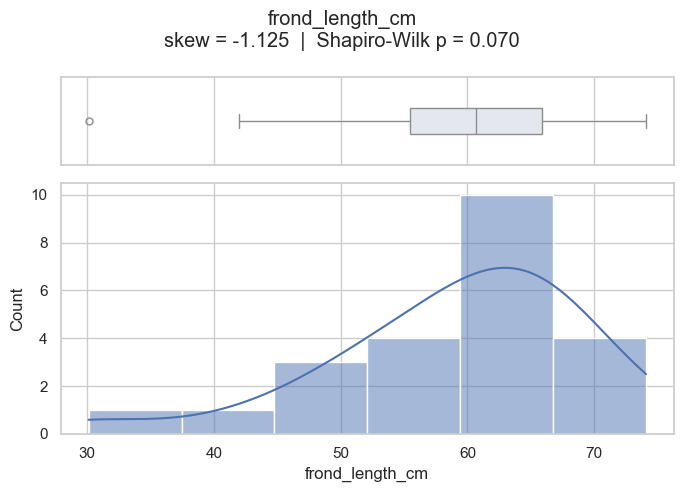

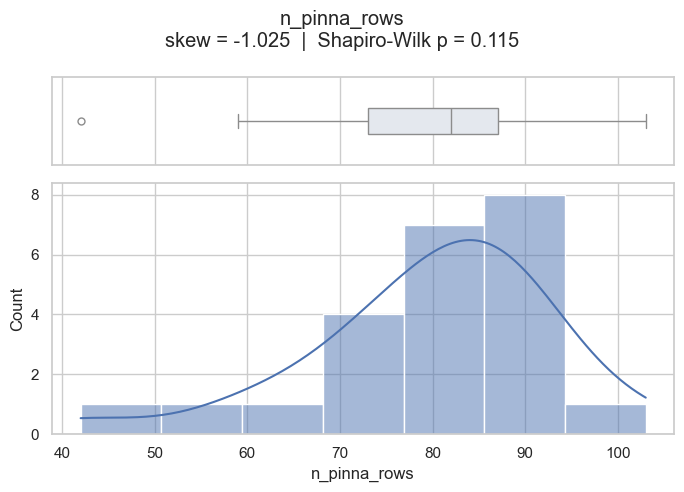

In [95]:
for col in ["frond_length_cm", "n_pinna_rows"]:
    plot_dist(df_fronds_notnull[col], col, figsize=(7, 5))

Skewness and Shapiro-Wilk results are less conclusive than for `n_sori_total`: both variables show marked skew (skew ≈ -1.1), but the Shapiro-Wilk test does not reject normality for either (p = 0.070 and p = 0.115, both above 0.05). However, both boxplots show a shared outlier, and Pearson correlation is sensitive to outliers regardless of whether the underlying distribution is normal. We therefore compute both Pearson and Spearman coefficients and compare them: if they are similar, the outlier is not driving the result; if they diverge substantially, it likely is.

In [96]:
r_pearson, p_pearson = pearsonr(df_fronds_notnull["frond_length_cm"], df_fronds_notnull["n_pinna_rows"])
rho_spearman, p_spearman = spearmanr(df_fronds_notnull["frond_length_cm"], df_fronds_notnull["n_pinna_rows"])

print(f"Pearson:  r   = {r_pearson:.3f}, p = {p_pearson:.3e}")
print(f"Spearman: rho = {rho_spearman:.3f}, p = {p_spearman:.3e}")

Pearson:  r   = 0.866, p = 9.358e-08
Spearman: rho = 0.722, p = 1.001e-04


The Pearson coefficient (r = 0.866, p < 0.001) is notably higher than the Spearman coefficient (rho = 0.72, p = 0.0001), a difference of nearly 0.15, indicating that the shared outlier is inflating the linear correlation. We therefore prioritize the Spearman coefficient as the more robust measure of this relationship.

This still supports the mechanistic hypothesis: longer fronds tend to have more pinna rows. However, this is not conclusive proof that length dominates area as a predictor of `n_sori_total`, the difference between their Spearman correlations with `n_sori_total` (0.63 vs. 0.62) remains marginal. This is left as a partial explanation, without ruling out the measurement-error sources discussed earlier.

### 4.6 Predictor Selection

The relationship between `frond_length_cm` and `n_pinna_rows` validated in Section 4.5 (Spearman rho = 0.72, p = 0.0001) is consistent with longer fronds having more pinna rows. `n_pinna_rows` itself also shows a moderate, statistically significant correlation with `n_sori_total` (Spearman rho = 0.56, p = 0.0055, Section 4.3). Together, these two relationships are consistent with frond length being associated with sori count partly through pinna row count, though this notebook does not test row count as a formal mediator of that relationship.

Independently of that mechanism, the Spearman matrix in Section 4.3 already showed that `n_sori_total` correlates strongly and significantly with both `frond_length_cm` (rho = 0.63, p = 0.0012) and `frond_width_cm` (rho = 0.67, p = 0.0004) directly. This gives confidence in using frond dimensions as reliable predictors, regardless of whether pinna row count is the full explanation for that relationship.

Given this identifiable and consistent linear relationship between sori count and frond dimensions, imputing H15's missing value with the group median would ignore this dependency structure, assigning a "typical" value without considering that H15's own frond dimensions reasonably predict its sori count. Multiple linear regression, by contrast, leverages this relationship to produce a more informed estimate, conditioned on the individual's specific morphometric characteristics.

We select `frond_length_cm` and `frond_width_cm` as predictors, since they show the strongest correlation with `n_sori_total`. Cook's distance will be evaluated later, during modeling, to quantify the influence of the outliers observed in the scatter plots on the fitted model.

## 5. Regression Modeling

We fit two regression models, Ordinary Least Squares (OLS) and Theil-Sen, using `frond_length_cm` and `frond_width_cm` as predictors of `n_sori_total`, and compare them to select the more reliable model for imputing H15.

### 5.1 Multiple Linear Regression (OLS)

In [97]:
X = df_fronds_notnull[["frond_length_cm", "frond_width_cm"]]
y_true = df_fronds_notnull["n_sori_total"]

X_const = sm.add_constant(X)  # adds the intercept (beta_0)
model_ols = sm.OLS(y_true, X_const).fit()

print(model_ols.summary())

                            OLS Regression Results                            
Dep. Variable:           n_sori_total   R-squared:                       0.411
Model:                            OLS   Adj. R-squared:                  0.352
Method:                 Least Squares   F-statistic:                     6.987
Date:               mar, 28 jul. 2026   Prob (F-statistic):            0.00500
Time:                        21:06:43   Log-Likelihood:                -165.64
No. Observations:                  23   AIC:                             337.3
Df Residuals:                      20   BIC:                             340.7
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            -578.5524    543.462     

The multiple linear regression model (`n_sori_total ~ frond_length_cm + frond_width_cm`) explains 41.1% of the variability in `n_sori_total` (adjusted R² = 0.352), and is significant overall (F = 6.987, p = 0.005). However, neither individual coefficient is statistically significant on its own (p = 0.169 and p = 0.101, respectively), attributable to strong collinearity between the two predictors (condition number = 454), which prevents precisely isolating each variable's individual effect despite their joint explanatory power. Model residuals are consistent with normality (Jarque-Bera p = 0.411) and show no autocorrelation (Durbin-Watson ≈ 2), so the model's basic assumptions hold reasonably well.

### 5.2 Regression Diagnostics: Cook's Distance

Since the model shows strong collinearity between predictors, it becomes especially relevant to check whether individual observations have a disproportionate influence on the fit. Collinearity can amplify the model's sensitivity to outliers: because predictors share variance, the estimation surface for the coefficients becomes unstable, and extreme observations can shift the solution more sharply than in a model without collinearity. For this reason, we compute Cook's distance for each individual, which quantifies how much the fitted model would change if that observation were excluded from the dataset, and compare each value against the conventional reference threshold of 4/n.

In [98]:
influence = OLSInfluence(model_ols)
cooks_d = influence.cooks_distance[0]

df_fronds_cooks = df_fronds_notnull.copy()
df_fronds_cooks["cooks_d"] = cooks_d.round(3)

threshold_cooks = 4 / len(df_fronds_notnull)  # reference rule: 4/n
print(f"Reference threshold (4/n): {threshold_cooks:.3f}\n")

df_fronds_cooks[["individual_id", "frond_length_cm", "frond_width_cm", "n_sori_total", "cooks_d"]] \
    .sort_values("cooks_d", ascending=False)

Reference threshold (4/n): 0.174



,individual_id,frond_length_cm,frond_width_cm,n_sori_total,cooks_d
12,H13,60.50,9.1,1170.0,1.082
1,H02,42.00,5.8,1554.0,0.233
18,H19,56.40,5.6,546.0,0.222
19,H20,49.00,5.8,482.0,0.137
11,H12,55.89,8.0,1966.0,0.122
7,H08,55.00,6.1,644.0,0.083
17,H18,74.10,7.9,2036.0,0.035
3,H04,66.00,7.1,1826.0,0.019
4,H05,60.70,6.0,1456.0,0.016
21,H22,56.20,6.2,1502.0,0.015


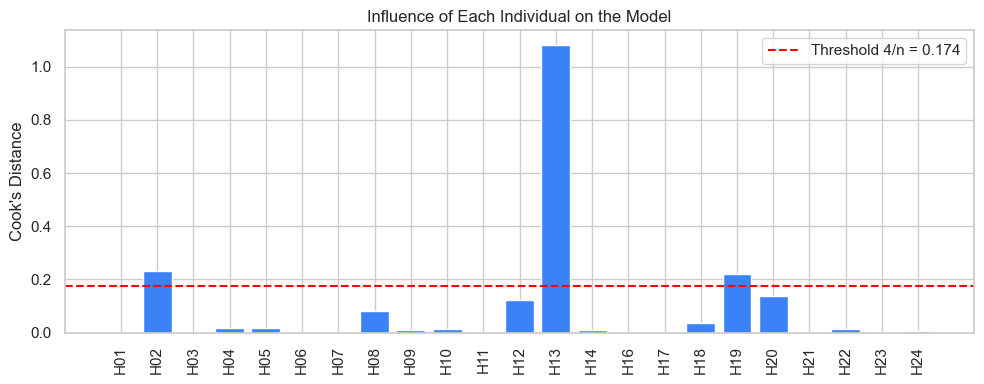

In [99]:
plt.figure(figsize=(10, 4))
plt.bar(df_fronds_cooks["individual_id"], df_fronds_cooks["cooks_d"], color="#3b82f6")
plt.axhline(threshold_cooks, color="red", linestyle="--", label=f"Threshold 4/n = {threshold_cooks:.3f}")
plt.xticks(rotation=90)
plt.ylabel("Cook's Distance")
plt.title("Influence of Each Individual on the Model")
plt.legend()
plt.tight_layout()
plt.show()

Cook's distance analysis shows that individual H13 exerts a disproportionately high influence on the regression model (Cook's D ≈ 1.08, well above the reference threshold of 4/n ≈ 0.174). H02 and H19 also exceed this threshold, though to a lesser extent. This indicates that the OLS-estimated slope may be distorted by these high-leverage points, compromising the model's reliability for use in imputation.

### 5.3 Leverage and Studentized Residuals

Since Cook's distance combines both leverage (how extreme an observation's predictor values are) and its residual (how far the observed value is from the model's prediction) into a single number, it cannot tell us on its own which of these two factors explains H13's influence. To disentangle this, we compute leverage (hat values) and studentized residuals separately for each observation, which lets us identify whether H13's influence stems mainly from an extreme predictor value, a poor model fit for that individual, or a combination of both.

In [100]:
df_fronds_cooks["leverage"] = influence.hat_matrix_diag.round(3)
df_fronds_cooks["studentized_resid"] = influence.resid_studentized_internal.round(3)

threshold_leverage = 2 * (2 + 1) / len(df_fronds_notnull)  # 2*(k+1)/n, with k=2 predictors
print(f"Reference threshold for leverage (2(k+1)/n): {threshold_leverage:.3f}\n")

df_fronds_cooks[["individual_id", "frond_length_cm", "frond_width_cm", "n_sori_total",
                 "cooks_d", "leverage", "studentized_resid"]] \
    .sort_values("cooks_d", ascending=False)

Reference threshold for leverage (2(k+1)/n): 0.261



,individual_id,frond_length_cm,frond_width_cm,n_sori_total,cooks_d,leverage,studentized_resid
12,H13,60.50,9.1,1170.0,1.082,0.382,-2.292
1,H02,42.00,5.8,1554.0,0.233,0.177,1.806
18,H19,56.40,5.6,546.0,0.222,0.158,-1.886
19,H20,49.00,5.8,482.0,0.137,0.110,-1.821
11,H12,55.89,8.0,1966.0,0.122,0.173,1.322
7,H08,55.00,6.1,644.0,0.083,0.079,-1.705
17,H18,74.10,7.9,2036.0,0.035,0.145,0.788
3,H04,66.00,7.1,1826.0,0.019,0.072,0.867
4,H05,60.70,6.0,1456.0,0.016,0.133,0.556
21,H22,56.20,6.2,1502.0,0.015,0.073,0.760


The leverage and studentized residual analysis reveals that H13's influence is not due to a single factor, but to a combination of both: it has the highest leverage in the dataset (0.382, against the reference threshold of 0.261), associated with an unusually large frond width (9.1 cm), together with a studentized residual of -2.292, which exceeds the conventional threshold of ±2 for outliers. This indicates that H13's observed sori count (1170) is notably lower than the model would predict given its frond width, compounding its impact on the estimated slope. By contrast, H02 and H19 show low leverage (0.177 and 0.158, respectively) and moderate residuals that do not reach the outlier threshold, so their influence on the model is considerably smaller. These results reinforce the need to contrast the OLS fit with a robust model such as Theil-Sen, which estimates the slope as the median of slopes between all pairs of points and is considerably less sensitive to extreme values.

### 5.4 Theil-Sen Regression

We refit the relationship using Theil-Sen, a robust regression method that estimates the slope as the median of slopes between all pairs of points, making it considerably less sensitive to the influence of H13 than OLS.

In [101]:
X = df_fronds_notnull[["frond_length_cm", "frond_width_cm"]].values
y_true = df_fronds_notnull["n_sori_total"].values

model_theil_sen = TheilSenRegressor(random_state=42)
model_theil_sen.fit(X, y_true)

print(f"Intercept (Theil-Sen): {model_theil_sen.intercept_:.2f}")
print(f"Coefficient frond_length_cm (Theil-Sen): {model_theil_sen.coef_[0]:.2f}")
print(f"Coefficient frond_width_cm (Theil-Sen): {model_theil_sen.coef_[1]:.2f}")

Intercept (Theil-Sen): -814.08
Coefficient frond_length_cm (Theil-Sen): 9.33
Coefficient frond_width_cm (Theil-Sen): 252.23


### 5.5 Standardized Coefficients (Theil-Sen)

`frond_length_cm` and `frond_width_cm` are on different scales, so comparing their raw coefficients directly does not tell us which one carries more relative weight in the prediction. To make this comparison valid, we standardize both predictors (z-scores) and refit the Theil-Sen model, the resulting coefficients, now on the same scale, represent "the change in `n_sori_total` per one standard deviation change in the predictor," and can be compared directly.

In [102]:
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

model_theil_sen_std = TheilSenRegressor(random_state=42)
model_theil_sen_std.fit(X_std, y_true)

print(f"Intercept (Theil-Sen, standardized): {model_theil_sen_std.intercept_:.2f}")
print(f"Coefficient frond_length_cm (standardized): {model_theil_sen_std.coef_[0]:.2f}")
print(f"Coefficient frond_width_cm (standardized): {model_theil_sen_std.coef_[1]:.2f}")

Intercept (Theil-Sen, standardized): 1484.28
Coefficient frond_length_cm (standardized): 125.91
Coefficient frond_width_cm (standardized): 182.56


The standardized coefficients show that `frond_width_cm` (182.56) carries relatively more weight than `frond_length_cm` (125.91) in predicting `n_sori_total`, once the scale difference between both variables is controlled for. This is consistent with the Spearman correlations observed earlier, where `frond_width_cm` showed a slightly stronger association with `n_sori_total` (0.67) than `frond_length_cm` (0.63).

### 5.6 OLS vs. Theil-Sen Comparison

We compare the coefficients estimated by both models directly, to quantify how much the OLS estimate is being distorted by H13's influence.

In [103]:
df_ols_vs_theilsen = pd.DataFrame({
    "parameter": ["intercept", "frond_length_cm", "frond_width_cm"],
    "OLS": [model_ols.params["const"], model_ols.params["frond_length_cm"], model_ols.params["frond_width_cm"]],
    "Theil-Sen": [model_theil_sen.intercept_, model_theil_sen.coef_[0], model_theil_sen.coef_[1]]
})
df_ols_vs_theilsen["pct_difference"] = (
    (df_ols_vs_theilsen["Theil-Sen"] - df_ols_vs_theilsen["OLS"]) / df_ols_vs_theilsen["OLS"] * 100
).round(1)
df_ols_vs_theilsen

,parameter,OLS,Theil-Sen,pct_difference
0,intercept,-578.552394,-814.078567,40.7
1,frond_length_cm,13.828173,9.333503,-32.5
2,frond_width_cm,169.156090,252.231274,49.1


The differences in coefficients between OLS and Theil-Sen (30-50%) confirm that the high-influence point (H13) distorts the estimated relative weights between `frond_length_cm` and `frond_width_cm`. This supports the decision to use the robust Theil-Sen model for imputation, since it more faithfully reflects the relationship between frond morphometrics and sori count, without the distortion introduced by outliers in predictor space.

### 5.7 Predictions Comparison: OLS vs. Theil-Sen

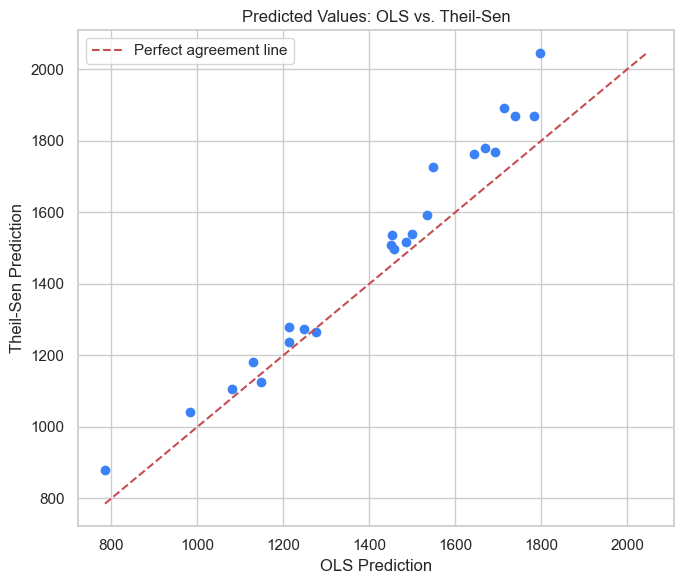

In [104]:
pred_ols = model_ols.fittedvalues
pred_theil_sen = model_theil_sen.predict(X)

plt.figure(figsize=(7, 6))
plt.scatter(pred_ols, pred_theil_sen, color="#3b82f6")
lims = [min(pred_ols.min(), pred_theil_sen.min()), max(pred_ols.max(), pred_theil_sen.max())]
plt.plot(lims, lims, "r--", label="Perfect agreement line")
plt.xlabel("OLS Prediction")
plt.ylabel("Theil-Sen Prediction")
plt.title("Predicted Values: OLS vs. Theil-Sen")
plt.legend()
plt.tight_layout()
plt.show()

Comparing the predictions of both models, they agree reasonably well in the lower range of `n_sori_total`, but diverge systematically as the predicted value increases: points fall consistently above the line of perfect agreement, indicating that Theil-Sen predicts higher values than OLS in that region. This is consistent with H13's influence identified earlier: having a relatively low observed `n_sori_total` despite its extreme frond width, this point flattens the OLS-estimated slope, compressing its predictions in the upper range. Being robust to this distortion, Theil-Sen produces a steeper slope and therefore higher predictions for individuals with greater `frond_width_cm`. This systematic divergence reinforces the decision to use Theil-Sen for imputing H15.

### 5.8 Model Selection

Based on the evidence gathered in this section, H13's disproportionate Cook's distance and leverage (5.2-5.3), the 30-50% shift in coefficients between OLS and Theil-Sen (5.6), and the systematic divergence in predictions concentrated in the upper range (5.7), we select **Theil-Sen** as the model used to impute H15's `n_sori_total` in Section 6.

## 6. Imputing H15

### 6.1 Predicting H15's n_sori_total

In [105]:
# H15's morphometric values
length_h15 = df_fronds_features.loc[df_fronds_features["individual_id"] == "H15", "frond_length_cm"].values[0]
width_h15 = df_fronds_features.loc[df_fronds_features["individual_id"] == "H15", "frond_width_cm"].values[0]

print(f"H15: frond_length_cm = {length_h15}, frond_width_cm = {width_h15}")

# Theil-Sen prediction
pred_h15_theil_sen = model_theil_sen.predict([[length_h15, width_h15]])[0]

# OLS prediction (for comparison)
pred_h15_ols = model_ols.params["const"] + model_ols.params["frond_length_cm"]*length_h15 + model_ols.params["frond_width_cm"]*width_h15

print(f"\nOLS prediction:       {pred_h15_ols:.1f}")
print(f"Theil-Sen prediction: {pred_h15_theil_sen:.1f}")
print(f"Difference: {abs(pred_h15_ols - pred_h15_theil_sen):.1f} ({abs(pred_h15_ols - pred_h15_theil_sen)/pred_h15_ols*100:.1f}%)")

H15: frond_length_cm = 47.3, frond_width_cm = 6.0

OLS prediction:       1090.5
Theil-Sen prediction: 1140.8
Difference: 50.3 (4.6%)


Applying both models to H15's actual morphometric values (`frond_length_cm` = 47.3, `frond_width_cm` = 6.0) yields a prediction of 1090.5 sori with OLS and 1140.8 with Theil-Sen, a difference of 50.3 sori (4.6%). Although the individual coefficients of both models differ considerably (30-50%, Section 5.6), the difference in the final prediction for H15 is notably smaller, since its morphometric values fall within the typical range of the dataset and are not close to the region where H13's distortion has the greatest effect. We adopt the Theil-Sen prediction (1140.8) as the point estimate for imputing H15, since it is the more reliable of the two, not conditioned on the disproportionate influence of outliers in the model fit. This value represents only the aggregate total; it does not indicate how sori are distributed along the frond.



### 6.2 Applying the Imputed Value

In [106]:
df_fronds_imputed = df_fronds_features.copy()

df_fronds_imputed["is_imputed"] = df_fronds_imputed["individual_id"] == "H15"
df_fronds_imputed.loc[df_fronds_imputed["individual_id"] == "H15", "n_sori_total"] = round(pred_h15_theil_sen)

df_fronds_imputed

,individual_id,frond_length_cm,frond_width_cm,n_sori_total,leaf_area_cm2,n_pinna_rows,is_imputed
0,H01,63.00,8.4,1656.0,280.0,86,False
1,H02,42.00,5.8,1554.0,130.0,59,False
2,H03,68.50,8.1,1728.0,266.0,80,False
3,H04,66.00,7.1,1826.0,216.0,89,False
4,H05,60.70,6.0,1456.0,194.0,82,False
5,H06,62.40,6.9,1290.0,229.0,85,False
6,H07,67.20,7.8,1590.0,287.0,91,False
7,H08,55.00,6.1,644.0,194.0,81,False
8,H09,66.00,6.8,1296.0,196.0,74,False
9,H10,51.30,6.4,1464.0,117.0,62,False


H15's `n_sori_total` is now set to 1141 (the rounded Theil-Sen prediction). `is_imputed` flags which row was estimated rather than measured, so anyone using this dataset downstream can filter or exclude imputed values explicitly.

As noted in `01_data_cleaning` (Section 4.2), `n_sori_total` was kept as `float64` because it still had a missing value at that stage. Now that H15's value has been imputed, `n_sori_total` has no missing values left, we convert it to a proper integer type before exporting, since a plain `int64` (rather than the nullable `Int64`) is sufficient once no `NaN` remains.

In [107]:
print(f"Missing values in n_sori_total: {df_fronds_imputed['n_sori_total'].isna().sum()}")

df_fronds_imputed["n_sori_total"] = df_fronds_imputed["n_sori_total"].astype("int64")
df_fronds_imputed.dtypes

Missing values in n_sori_total: 0


individual_id       object
frond_length_cm    float64
frond_width_cm     float64
n_sori_total         int64
leaf_area_cm2      float64
n_pinna_rows         int64
is_imputed            bool
dtype: object

### 6.3 Post-Imputation Distribution Check



Before exporting, we check H15's imputed value against the completed population, its position in the overall distribution, and its fit against the same predictors used to generate it, to confirm the imputed value looks consistent with the real data rather than anomalous. Recomputing the correlation matrix here would be circular (H15's value was itself derived from these same variables), so this check is visual rather than statistical.

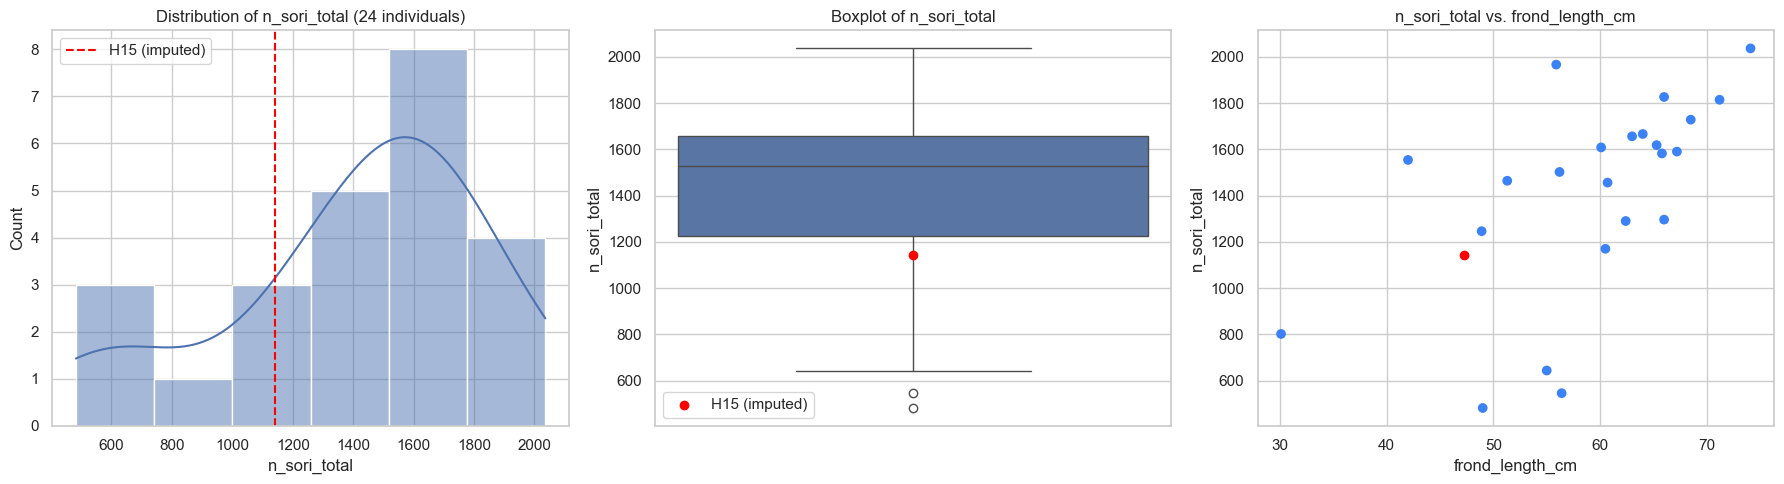

In [109]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_fronds_imputed["n_sori_total"], kde=True, ax=axes[0])
axes[0].axvline(df_fronds_imputed.loc[df_fronds_imputed["individual_id"] == "H15", "n_sori_total"].values[0],
                color="red", linestyle="--", label="H15 (imputed)")
axes[0].set_title("Distribution of n_sori_total (24 individuals)")
axes[0].legend()

sns.boxplot(y=df_fronds_imputed["n_sori_total"], ax=axes[1])
axes[1].scatter(0, df_fronds_imputed.loc[df_fronds_imputed["individual_id"] == "H15", "n_sori_total"].values[0],
                color="red", zorder=5, label="H15 (imputed)")
axes[1].set_title("Boxplot of n_sori_total")
axes[1].legend()

colors = df_fronds_imputed["is_imputed"].map({True: "red", False: "#3b82f6"})
axes[2].scatter(df_fronds_imputed["frond_length_cm"], df_fronds_imputed["n_sori_total"], c=colors)
axes[2].set_xlabel("frond_length_cm")
axes[2].set_ylabel("n_sori_total")
axes[2].set_title("n_sori_total vs. frond_length_cm")

plt.tight_layout()
plt.savefig("../outputs/figures/02_post_imputation_check.png", dpi=300, bbox_inches="tight")
plt.show()

H15's imputed value (1141) falls within the observed range of `n_sori_total` and is not flagged as a statistical outlier in the boxplot, it sits below the median but within the whiskers, in the same region as several other real individuals. In the scatter against `frond_length_cm`, H15 sits somewhat below other individuals of similar length, though still within the overall upward trend rather than departing from it. This is consistent with the residual spread already documented for the Theil-Sen model in Section 5, no single predictor captures `n_sori_total` perfectly, and H15's imputed value reflects that same expected uncertainty rather than an anomaly introduced by the imputation itself.

## 7. Export Imputed Dataset

We export `df_fronds_imputed`, which includes `n_pinna_rows` and H15's imputed `n_sori_total`, to `data/processed/`, so the next notebook in the pipeline, focused on imputing H15's row-level sori distribution, can load it directly.

In [110]:
df_fronds_imputed.to_csv("../data/processed/fronds_imputed.csv", index=False)

print(f"df_fronds_imputed exported: {df_fronds_imputed.shape[0]} rows × {df_fronds_imputed.shape[1]} columns")

df_fronds_imputed exported: 24 rows × 7 columns


H15's `n_sori_total` has been imputed using a Theil-Sen regression on frond morphometrics, selected over OLS due to the disproportionate influence of individual H13. The imputed dataset is exported with full traceability (`is_imputed`) for the next notebook, which addresses H15's missing row-level sori distribution.